# Faceta 1: reducción de dimensionalidad de las activaciones internas

Extrae las activaciones del cuello del U-Net en cada paso del muestreo, y las proyecta a 2D con PCA. Permite ver:

1. la trayectoria del muestreo de ruido a flor en el espacio de features (= la EDE reversa vista en el espacio semántico, no en pixeles);
2. la comparación eta=0 vs eta=1: mismo punto de partida (misma semilla), caminos distintos, mismo destino.

## 0. Entorno y Drive

In [ ]:
import torch
from google.colab import drive
drive.mount('/content/drive')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)

Mounted at /content/drive
device: cuda


## 1. Configuracion

In [ ]:
CKPT = '/content/drive/MyDrive/flower-diffusion/latente/latent_oracle.pt'   # oraculo latente entrenado

## 2. Clases del modelo y difusión

In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class TimeEmbedding(nn.Module):
    def __init__(self, time_emb_dim):
        super().__init__()
        self.linear1 = nn.Linear(time_emb_dim, time_emb_dim * 4)
        self.linear2 = nn.Linear(time_emb_dim * 4, time_emb_dim)
        self.act = nn.SiLU()
    def get_sinusoidal_embedding(self, t, dim):
        half = dim // 2
        emb = math.log(10000) / (half - 1)
        emb = torch.exp(torch.arange(half, device=t.device) * -emb)
        emb = t.float().unsqueeze(1) * emb.unsqueeze(0)
        return torch.cat([torch.sin(emb), torch.cos(emb)], dim=1)
    def forward(self, t, dim):
        x = self.get_sinusoidal_embedding(t, dim)
        x = self.act(self.linear1(x))
        return self.linear2(x)

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_emb_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.act = nn.SiLU()
        self.time_proj = nn.Linear(time_emb_dim, out_ch)
        self.residual = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x, t_emb):
        h = self.act(self.norm1(self.conv1(x)))
        t = self.act(self.time_proj(t_emb))
        h = h + t[:, :, None, None]
        h = self.act(self.norm2(self.conv2(h)))
        return h + self.residual(x)

class Downsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.op = nn.Conv2d(ch, ch, 3, stride=2, padding=1)
    def forward(self, x):
        return self.op(x)

class Upsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, padding=1)
    def forward(self, x):
        x = F.interpolate(x, scale_factor=2, mode='nearest')
        return self.conv(x)

class AttentionBlock(nn.Module):
    def __init__(self, channels, num_heads=4):
        super().__init__()
        assert channels % num_heads == 0
        self.num_heads = num_heads
        self.norm = nn.GroupNorm(8, channels)
        self.qkv = nn.Conv2d(channels, channels * 3, 1)
        self.proj = nn.Conv2d(channels, channels, 1)
    def forward(self, x):
        B, C, H, W = x.shape
        q, k, v = self.qkv(self.norm(x)).chunk(3, dim=1)
        dh = C // self.num_heads
        q = q.reshape(B, self.num_heads, dh, H * W)
        k = k.reshape(B, self.num_heads, dh, H * W)
        v = v.reshape(B, self.num_heads, dh, H * W)
        attn = torch.softmax(torch.einsum('bhcn,bhcm->bhnm', q, k) / math.sqrt(dh), dim=-1)
        out = torch.einsum('bhnm,bhcm->bhcn', attn, v).reshape(B, C, H, W)
        return x + self.proj(out)

class UNet(nn.Module):
    def __init__(self, in_channels=4, base_channels=128, channel_mults=(1, 2, 4),
                 num_res_blocks=2, attn_resolutions=(16,), time_emb_dim=128, image_size=32):
        super().__init__()
        self.time_emb_dim = time_emb_dim
        self.time_embedding = TimeEmbedding(time_emb_dim)
        self.init_conv = nn.Conv2d(in_channels, base_channels, 3, padding=1)
        self.downs = nn.ModuleList(); chs = [base_channels]; now = base_channels; res = image_size
        for i, m in enumerate(channel_mults):
            out = base_channels * m
            for _ in range(num_res_blocks):
                blk = nn.ModuleList([ResBlock(now, out, time_emb_dim)]); now = out
                if res in attn_resolutions: blk.append(AttentionBlock(now))
                self.downs.append(blk); chs.append(now)
            if i != len(channel_mults) - 1:
                self.downs.append(nn.ModuleList([Downsample(now)])); chs.append(now); res //= 2
        self.mid_block1 = ResBlock(now, now, time_emb_dim)
        self.mid_attn = AttentionBlock(now)
        self.mid_block2 = ResBlock(now, now, time_emb_dim)
        self.ups = nn.ModuleList()
        for i, m in reversed(list(enumerate(channel_mults))):
            out = base_channels * m
            for _ in range(num_res_blocks + 1):
                blk = nn.ModuleList([ResBlock(now + chs.pop(), out, time_emb_dim)]); now = out
                if res in attn_resolutions: blk.append(AttentionBlock(now))
                self.ups.append(blk)
            if i != 0:
                self.ups.append(nn.ModuleList([Upsample(now)])); res *= 2
        self.out_norm = nn.GroupNorm(8, now); self.out_act = nn.SiLU()
        self.out_conv = nn.Conv2d(now, in_channels, 3, padding=1)
    def forward(self, x, t):
        t_emb = self.time_embedding(t, dim=self.time_emb_dim)
        h = self.init_conv(x); skips = [h]
        for blk in self.downs:
            if isinstance(blk[0], Downsample): h = blk[0](h)
            else:
                h = blk[0](h, t_emb)
                if len(blk) > 1: h = blk[1](h)
            skips.append(h)
        h = self.mid_block1(h, t_emb); h = self.mid_attn(h); h = self.mid_block2(h, t_emb)
        for blk in self.ups:
            if isinstance(blk[0], Upsample): h = blk[0](h)
            else:
                h = torch.cat([h, skips.pop()], dim=1)
                h = blk[0](h, t_emb)
                if len(blk) > 1: h = blk[1](h)
        return self.out_conv(self.out_act(self.out_norm(h)))

class DiffusionProcess:
    def __init__(self, T=1000, beta_start=1e-4, beta_end=0.02, device='cuda'):
        self.T = T; self.device = device
        self.betas = torch.linspace(beta_start, beta_end, T, device=device)
        self.alphas = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)

## 3. Cargar el oráculo (pesos EMA)

In [ ]:
# [IA] Carga del oráculo entrenado (pesos EMA)
# desde el checkpoint, con apoyo de IA.

def build_latent_model(cfg, device):
    return UNet(in_channels=cfg['latent_ch'], base_channels=cfg['base_channels'],
                channel_mults=tuple(cfg['channel_mults']), num_res_blocks=cfg['num_res_blocks'],
                attn_resolutions=tuple(cfg['attn_resolutions']), time_emb_dim=cfg['time_emb_dim'],
                image_size=cfg['latent_size']).to(device)

ckpt = torch.load(CKPT, map_location=DEVICE)
cfg = ckpt['config']
latent_model = build_latent_model(cfg, DEVICE)
latent_model.load_state_dict(ckpt['ema_state_dict'])   # pesos EMA
latent_model.eval()
diffusion = DiffusionProcess(cfg['T'], cfg['beta_start'], cfg['beta_end'], DEVICE)
print('modelo cargado | latente', cfg['latent_ch'], 'x', cfg['latent_size'], 'x', cfg['latent_size'])

modelo cargado | latente 4 x 32 x 32


## 4. Muestreo con captura del cuello (forward hook)

El hook se engancha a `mid_block2` (la salida del cuello). Cada vez que el muestreo llama al modelo, el hook guarda esa activacion. Al final hay una por paso.

In [ ]:
# [IA] Captura de activaciones del cuello con forward hook (register_forward_hook)
# durante el muestreo: implementada con apoyo de IA.

import numpy as np

@torch.no_grad()
def sample_capturando_cuello(model, diffusion, n, steps, eta, cfg, device=DEVICE, seed=None):
    """Corre el muestreo y, con un forward hook, guarda la activacion del cuello
    (salida de mid_block2, forma (n,512,8,8)) en cada paso. Devuelve el latente
    final y un array (steps, n, D) con las activaciones aplanadas por muestra."""
    if seed is not None:
        torch.manual_seed(seed)
    model.eval()

    # --- enganchamos el oyente al cuello ---
    capturas = []
    def hook(modulo, entrada, salida):
        capturas.append(salida.detach().float().cpu())
    handle = model.mid_block2.register_forward_hook(hook)

    T = diffusion.T
    tiempos = np.linspace(0, T - 1, steps + 1).round().astype(int)[::-1]
    x = torch.randn(n, cfg['latent_ch'], cfg['latent_size'], cfg['latent_size'], device=device)
    try:
        for i in range(steps):
            t_actual = int(tiempos[i]); t_sig = int(tiempos[i + 1])
            ab_t = diffusion.alpha_bars[t_actual]; ab_s = diffusion.alpha_bars[t_sig]
            t_batch = torch.full((n,), t_actual, device=device, dtype=torch.long)
            eps = model(x, t_batch)
            x0 = (x - torch.sqrt(1 - ab_t) * eps) / torch.sqrt(ab_t)
            sigma = eta * torch.sqrt((1 - ab_s) / (1 - ab_t)) * torch.sqrt(1 - ab_t / ab_s)
            coef = torch.sqrt(torch.clamp(1 - ab_s - sigma ** 2, min=0.0))
            z = torch.randn_like(x) if i < steps - 1 else torch.zeros_like(x)
            x = torch.sqrt(ab_s) * x0 + coef * eps + sigma * z
    finally:
        handle.remove()

    # capturas: lista de (n,512,8,8) -> array (steps, n, D)
    acts = torch.stack(capturas, dim=0).reshape(steps, n, -1).numpy()
    return x, acts

## 5. Correr para eta=0 y eta=1 (misma semilla)

In [ ]:
# --- parametros de la corrida ---
N_MUESTRAS = 3        # cuantas trayectorias por cada eta
STEPS = 50
SEED = 0              # misma semilla para eta=0 y eta=1 -> parten del MISMO ruido

# eta=0 (determinista, DDIM)
_, acts_eta0 = sample_capturando_cuello(latent_model, diffusion, N_MUESTRAS, STEPS, eta=0.0, cfg=cfg, seed=SEED)
# eta=1 (estocastico, DDPM)
_, acts_eta1 = sample_capturando_cuello(latent_model, diffusion, N_MUESTRAS, STEPS, eta=1.0, cfg=cfg, seed=SEED)

print('activaciones eta=0:', acts_eta0.shape, '| eta=1:', acts_eta1.shape, '  (steps, muestras, dim)')

activaciones eta=0: (50, 3, 32768) | eta=1: (50, 3, 32768)   (steps, muestras, dim)


## 6. PCA y grafico de trayectorias

PCA ajustada sobre las activaciones de ambos eta juntas, para que las dos familias de trayectorias vivan en el mismo plano y sean comparables.

varianza explicada por PC1, PC2: 17.7%, 12.7%


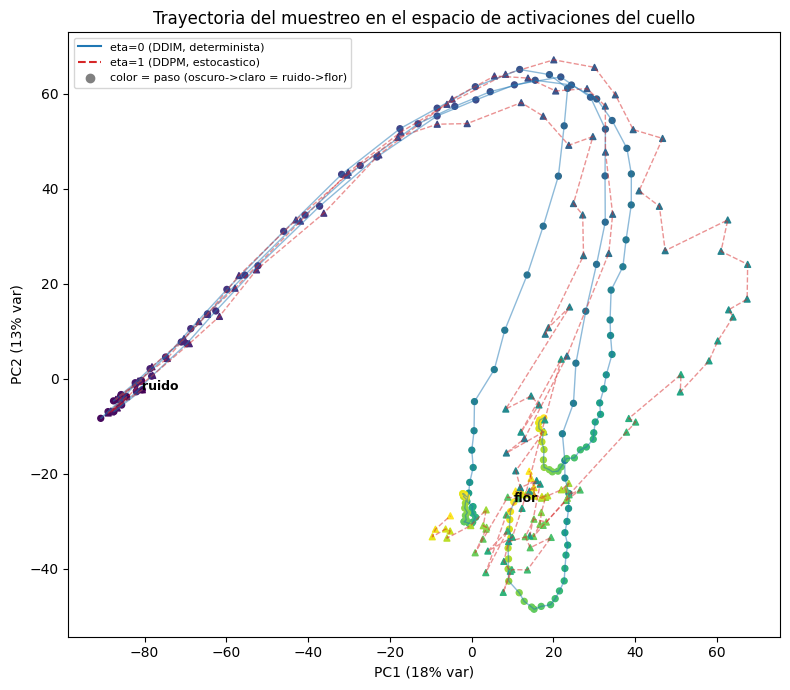

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --- PCA ajustada sobre TODO (ambos eta) para que vivan en el mismo plano ---
D = acts_eta0.shape[-1]
todo = np.concatenate([acts_eta0.reshape(-1, D), acts_eta1.reshape(-1, D)], axis=0)
pca = PCA(n_components=2).fit(todo)
var = pca.explained_variance_ratio_
print(f'varianza explicada por PC1, PC2: {var[0]:.1%}, {var[1]:.1%}')

def proyectar(acts):
    steps, n, _ = acts.shape
    p = pca.transform(acts.reshape(-1, D)).reshape(steps, n, 2)
    return p

P0 = proyectar(acts_eta0)   # (steps, n, 2)
P1 = proyectar(acts_eta1)

# --- grafico: trayectorias ruido -> flor, eta=0 vs eta=1 ---
fig, ax = plt.subplots(figsize=(8, 7))
cmap = plt.cm.viridis
for n in range(N_MUESTRAS):
    # eta=0: linea solida
    xy = P0[:, n, :]
    ax.plot(xy[:, 0], xy[:, 1], '-', color='tab:blue', alpha=0.5, lw=1)
    ax.scatter(xy[:, 0], xy[:, 1], c=np.arange(STEPS), cmap=cmap, s=18, marker='o')
    # eta=1: linea punteada
    xy = P1[:, n, :]
    ax.plot(xy[:, 0], xy[:, 1], '--', color='tab:red', alpha=0.5, lw=1)
    ax.scatter(xy[:, 0], xy[:, 1], c=np.arange(STEPS), cmap=cmap, s=18, marker='^')
    # marcar inicio (ruido) y fin (flor) de una de las trayectorias
    if n == 0:
        ax.annotate('ruido', P0[0, n, :], fontsize=9, weight='bold')
        ax.annotate('flor',  P0[-1, n, :], fontsize=9, weight='bold')

ax.set_xlabel(f'PC1 ({var[0]:.0%} var)'); ax.set_ylabel(f'PC2 ({var[1]:.0%} var)')
ax.set_title('Trayectoria del muestreo en el espacio de activaciones del cuello')
leyenda = [Line2D([0],[0], color='tab:blue', ls='-', label='eta=0 (DDIM, determinista)'),
           Line2D([0],[0], color='tab:red', ls='--', label='eta=1 (DDPM, estocastico)'),
           Line2D([0],[0], marker='o', color='gray', ls='', label='color = paso (oscuro->claro = ruido->flor)')]
ax.legend(handles=leyenda, loc='best', fontsize=8)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/flower-diffusion/latente/pca_trayectorias.png', dpi=150, bbox_inches='tight')
plt.show()

## 6b. Largo de arco: cuantificar el "zigzag"

El largo de arco de una trayectoria es la suma de las distancias entre pasos consecutivos. Lo medimos en el espacio completo de activaciones y en el plano PCA.

Largo de arco (promedio sobre muestras):
  espacio completo: eta=0 = 661.0   eta=1 = 1784.6   razon = 2.70x
  plano PCA (2D):   eta=0 = 265.7   eta=1 = 366.7   razon = 1.38x


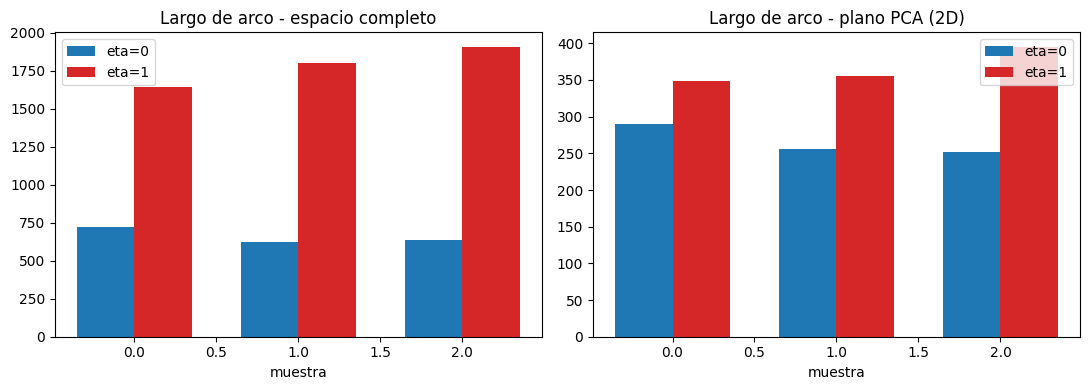

In [ ]:
def largo_arco(traj):
    # traj: (steps, n, dim) -> largo por muestra (n,)
    dif = np.diff(traj, axis=0)              # diferencias entre pasos consecutivos
    pasos = np.linalg.norm(dif, axis=-1)     # distancia de cada tramo
    return pasos.sum(axis=0)                  # suma = largo total

# espacio completo de activaciones
L0_full = largo_arco(acts_eta0)
L1_full = largo_arco(acts_eta1)
# plano PCA (2D) -- P0, P1 ya calculados
L0_pca = largo_arco(P0)
L1_pca = largo_arco(P1)

print("Largo de arco (promedio sobre muestras):")
print(f"  espacio completo: eta=0 = {L0_full.mean():.1f}   eta=1 = {L1_full.mean():.1f}   razon = {L1_full.mean()/L0_full.mean():.2f}x")
print(f"  plano PCA (2D):   eta=0 = {L0_pca.mean():.1f}   eta=1 = {L1_pca.mean():.1f}   razon = {L1_pca.mean()/L0_pca.mean():.2f}x")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
idx = np.arange(N_MUESTRAS); w = 0.35
ax[0].bar(idx - w/2, L0_full, w, label='eta=0', color='tab:blue')
ax[0].bar(idx + w/2, L1_full, w, label='eta=1', color='tab:red')
ax[0].set_title('Largo de arco - espacio completo'); ax[0].set_xlabel('muestra'); ax[0].legend()
ax[1].bar(idx - w/2, L0_pca, w, label='eta=0', color='tab:blue')
ax[1].bar(idx + w/2, L1_pca, w, label='eta=1', color='tab:red')
ax[1].set_title('Largo de arco - plano PCA (2D)'); ax[1].set_xlabel('muestra'); ax[1].legend()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/flower-diffusion/latente/pca_largo_arco.png', dpi=150, bbox_inches='tight')
plt.show()

## Faceta 2: features de las activaciones (centroide y tamaño)

Define propiedades interpretables de la flor que emerge, a partir de las activaciones. Como el modelo es incondicional (sin texto), adaptamos self-guidance: en vez de la atención a un token de texto, usamos un mapa de saliencia = la energia (norma sobre canales) del último mapa de
features del U-Net (a 32x32). De ese mapa sacamos:
- **centroide**: centro de masa de la saliencia -> dónde esta la flor;
- **tamaño**: fraccion del lienzo sobre un umbral suave -> cuánto ocupa.

In [ ]:
# [IA] Construcción del mapa de saliencia (norma de las activaciones sobre los canales)
# y de los features derivados (centroide y tamaño): implementado con apoyo de IA.

@torch.no_grad()
def sample_capturando_final(model, diffusion, n, steps, eta, cfg, device=DEVICE, seed=None):
    """El hook captura el ultimo mapa de features (salida de out_act,
    forma (n,128,32,32)) en cada paso. Resolucion 32x32: sirve para ubicar la flor."""
    if seed is not None:
        torch.manual_seed(seed)
    model.eval()
    capturas = []
    def hook(m, entrada, salida):
        capturas.append(salida.detach().float().cpu())
    handle = model.out_act.register_forward_hook(hook)
    T = diffusion.T
    tiempos = np.linspace(0, T - 1, steps + 1).round().astype(int)[::-1]
    x = torch.randn(n, cfg['latent_ch'], cfg['latent_size'], cfg['latent_size'], device=device)
    try:
        for i in range(steps):
            t_actual = int(tiempos[i]); t_sig = int(tiempos[i + 1])
            ab_t = diffusion.alpha_bars[t_actual]; ab_s = diffusion.alpha_bars[t_sig]
            t_batch = torch.full((n,), t_actual, device=device, dtype=torch.long)
            eps = model(x, t_batch)
            x0 = (x - torch.sqrt(1 - ab_t) * eps) / torch.sqrt(ab_t)
            sigma = eta * torch.sqrt((1 - ab_s) / (1 - ab_t)) * torch.sqrt(1 - ab_t / ab_s)
            coef = torch.sqrt(torch.clamp(1 - ab_s - sigma ** 2, min=0.0))
            z = torch.randn_like(x) if i < steps - 1 else torch.zeros_like(x)
            x = torch.sqrt(ab_s) * x0 + coef * eps + sigma * z
    finally:
        handle.remove()
    feats = torch.stack(capturas, dim=0).numpy()   # (steps, n, 128, 32, 32)
    return feats

def saliencia(feat):
    # feat: (n,C,H,W) -> mapa (n,H,W): energia (norma sobre canales) por posicion
    return np.linalg.norm(feat, axis=1)

def centroide(S):
    # S: (n,H,W) -> (n,2) centro de masa en coords [0,1] (x derecha, y hacia abajo)
    n, H, W = S.shape
    ys, xs = np.mgrid[0:H, 0:W]
    out = []
    for i in range(n):
        A = S[i]; Z = A.sum() + 1e-8
        cx = (xs * A).sum() / Z / (W - 1)
        cy = (ys * A).sum() / Z / (H - 1)
        out.append([cx, cy])
    return np.array(out)

def tamano(S):
    # S: (n,H,W) -> (n,): fraccion del lienzo sobre umbral suave (punto medio min-max)
    n, H, W = S.shape
    out = []
    for i in range(n):
        A = S[i]; thr = 0.5 * (A.min() + A.max())
        out.append((A > thr).mean())
    return np.array(out)

N_MUESTRAS = 3
STEPS = 50
feats = sample_capturando_final(latent_model, diffusion, N_MUESTRAS, STEPS, eta=0.0, cfg=cfg, seed=0)
S = np.stack([saliencia(feats[s]) for s in range(STEPS)], axis=0)   # (steps, n, 32, 32)
cent = np.stack([centroide(S[s]) for s in range(STEPS)], axis=0)    # (steps, n, 2)
tam = np.stack([tamano(S[s]) for s in range(STEPS)], axis=0)        # (steps, n)
print('saliencia:', S.shape, '| centroide:', cent.shape, '| tamano:', tam.shape)

saliencia: (50, 3, 32, 32) | centroide: (50, 3, 2) | tamano: (50, 3)


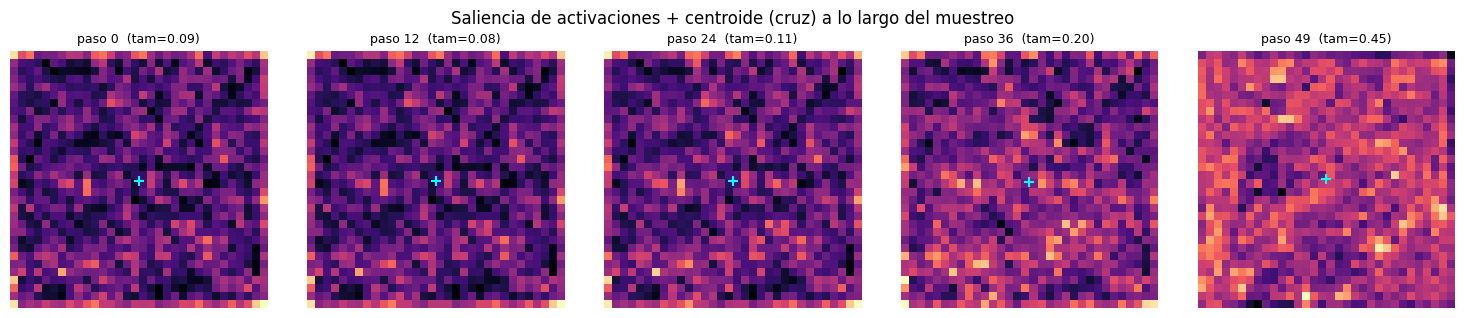

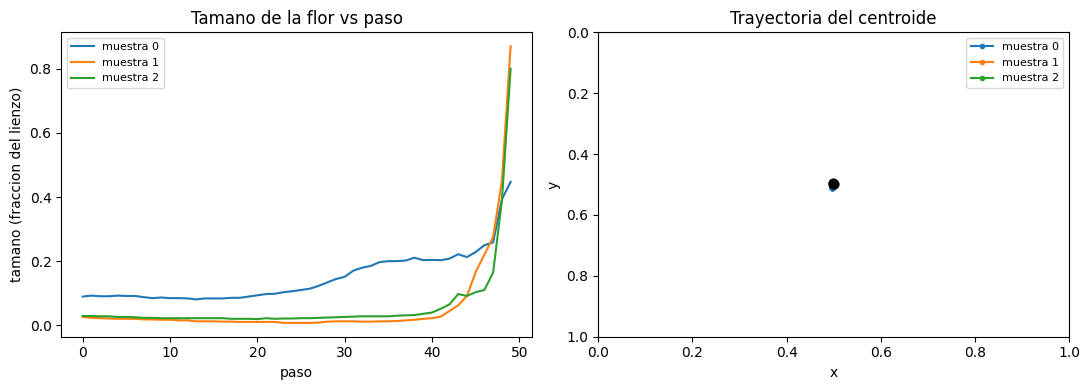

In [ ]:
muestra = 0
pasos_mostrar = [0, 12, 24, 36, 49]

fig, axes = plt.subplots(1, len(pasos_mostrar), figsize=(3 * len(pasos_mostrar), 3.2))
for ax, p in zip(axes, pasos_mostrar):
    ax.imshow(S[p, muestra], cmap='magma')
    cx, cy = cent[p, muestra]
    ax.scatter([cx * (S.shape[-1] - 1)], [cy * (S.shape[-2] - 1)], c='cyan', s=60, marker='+')
    ax.set_title(f'paso {p}  (tam={tam[p, muestra]:.2f})', fontsize=9)
    ax.axis('off')
fig.suptitle('Saliencia de activaciones + centroide (cruz) a lo largo del muestreo')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for n in range(N_MUESTRAS):
    ax[0].plot(tam[:, n], label=f'muestra {n}')
ax[0].set_xlabel('paso'); ax[0].set_ylabel('tamano (fraccion del lienzo)')
ax[0].set_title('Tamano de la flor vs paso'); ax[0].legend(fontsize=8)
for n in range(N_MUESTRAS):
    ax[1].plot(cent[:, n, 0], cent[:, n, 1], '-o', ms=3, label=f'muestra {n}')
    ax[1].scatter([cent[-1, n, 0]], [cent[-1, n, 1]], c='k', s=40, zorder=5)
ax[1].set_xlim(0, 1); ax[1].set_ylim(1, 0)
ax[1].set_xlabel('x'); ax[1].set_ylabel('y')
ax[1].set_title('Trayectoria del centroide'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Faceta 2b: feature de apariencia (color/estilo)

Siguiendo al paper, el feature de apariencia es el **promedio espacial de las
activaciones** del cuello -> un vector por flor que resume color/estilo, sin necesidad de localizar.
Lo validamos mostrando que ese vector se alinea con el **color real** de la flor decodificada.

In [ ]:
# [IA] Carga del VAE para decodificar, con apoyo de IA.

!pip -q uninstall -y torchao
!pip -q install -U diffusers safetensors
from diffusers import AutoencoderKL

vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").to(DEVICE).eval()
for p in vae.parameters():
    p.requires_grad_(False)
SCALE = vae.config.scaling_factor

@torch.no_grad()
def decode(z):
    return vae.decode(z / SCALE).sample.clamp(-1, 1)
print("VAE cargado")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

VAE cargado


In [ ]:
# Generar varias flores capturando (a) el latente final y (b) el vector de apariencia
N = 24
STEPS = 50
x_final, acts = sample_capturando_cuello(latent_model, diffusion, N, STEPS, eta=0.0, cfg=cfg, seed=0)

# apariencia = promedio espacial (GAP) de la ultima activacion del cuello -> (N, 512)
C = 512
apariencia = acts[-1].reshape(N, C, -1).mean(axis=2)

# decodificar los latentes a imagenes para tener el color real
imgs = ((decode(x_final).cpu() + 1) / 2).clamp(0, 1).numpy()   # (N,3,256,256) en [0,1]
color_real = imgs.mean(axis=(2, 3))                            # (N,3) color medio RGB
print("apariencia:", apariencia.shape, "| imgs:", imgs.shape, "| color_real:", color_real.shape)

apariencia: (24, 512) | imgs: (24, 3, 256, 256) | color_real: (24, 3)


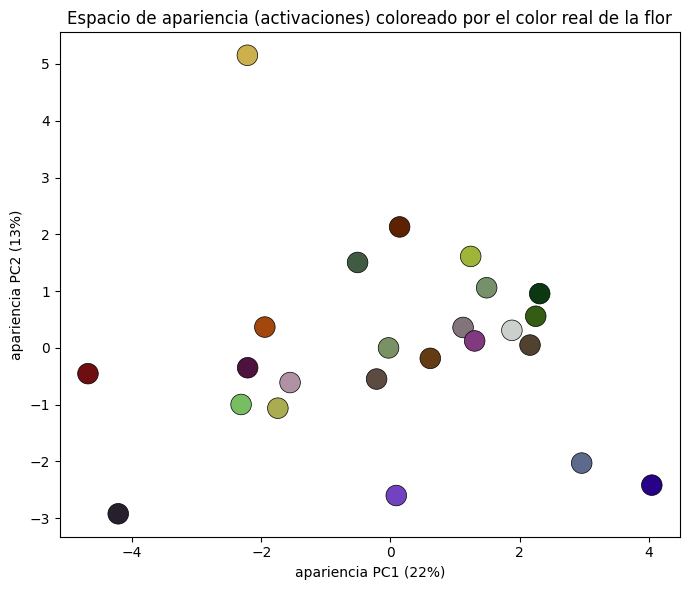

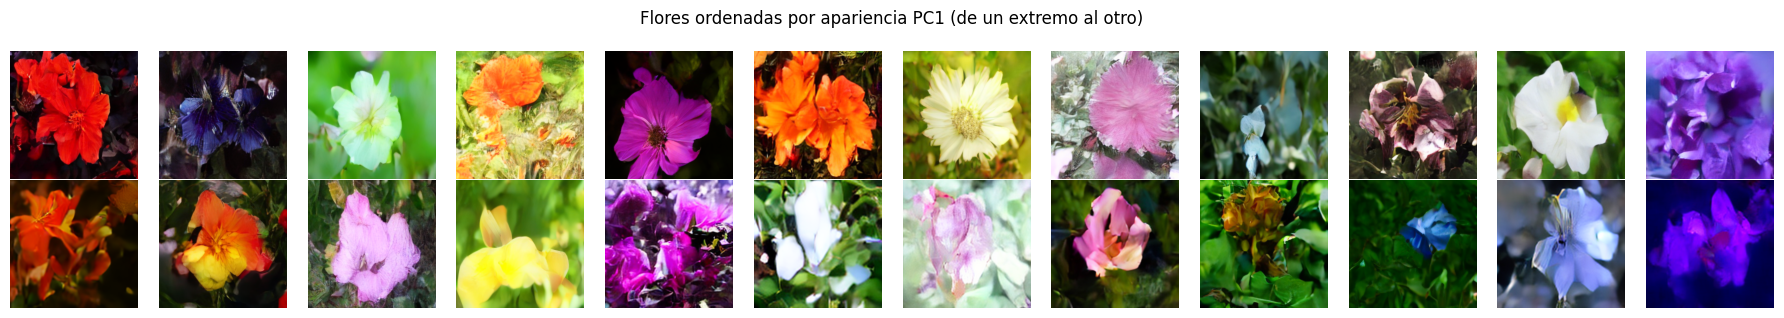

In [ ]:
from sklearn.decomposition import PCA

# PCA del vector de apariencia a 2D
pca_ap = PCA(n_components=2).fit(apariencia)
A2 = pca_ap.transform(apariencia)
var = pca_ap.explained_variance_ratio_

# (1) scatter en el espacio de apariencia, cada punto pintado con el color REAL de su flor
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(A2[:, 0], A2[:, 1], c=color_real, s=220, edgecolors='k', linewidths=0.5)
ax.set_xlabel(f'apariencia PC1 ({var[0]:.0%})'); ax.set_ylabel(f'apariencia PC2 ({var[1]:.0%})')
ax.set_title('Espacio de apariencia (activaciones) coloreado por el color real de la flor')
plt.tight_layout(); plt.show()

# (2) miniaturas ordenadas por apariencia-PC1
orden = np.argsort(A2[:, 0])
fig, axes = plt.subplots(2, 12, figsize=(18, 3.2))
for ax, idx in zip(axes.ravel(), orden):
    ax.imshow(imgs[idx].transpose(1, 2, 0)); ax.axis('off')
fig.suptitle('Flores ordenadas por apariencia PC1 (de un extremo al otro)')
plt.tight_layout(); plt.show()

## Faceta 2c: segmentacion de partes (petalos / hojas / fondo)

Dentro del U-Net, cada posición tiene un vector de activaciones que codifica qué hay ahí, así que pétalo, hoja y fondo producen vectores parecidos. Agrupándolos con k-means (no supervisado, sin texto) salen regiones que corresponden a las partes de la flor. Lo hacemos sobre una flor generada a la que le reinyectamos ruido a un nivel intermedio (donde las activaciones son más semánticas) y superponemos el mapa de partes sobre la flor.

Probamos dos niveles de ruido.

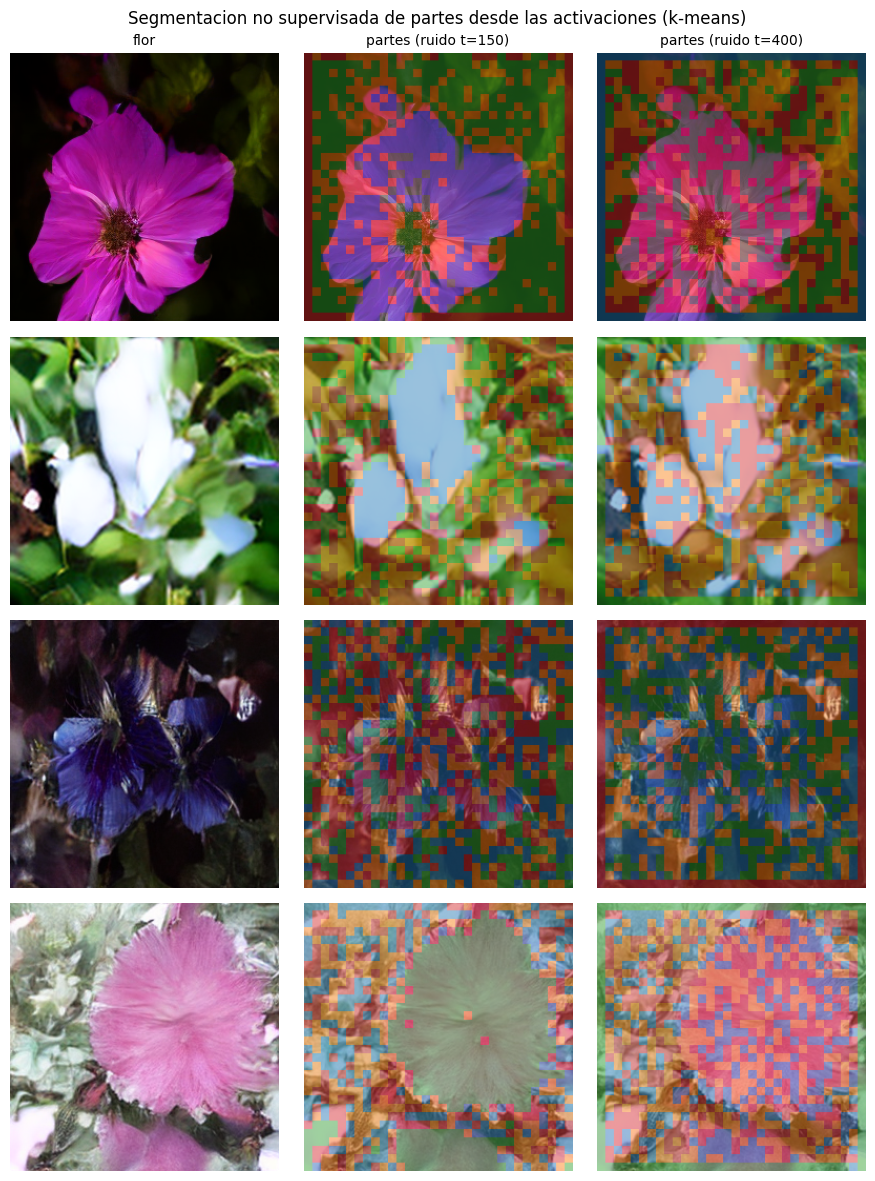

In [ ]:
# [IA] Segmentación no supervisada de partes: promediado de activaciones por re-ruido
# (features_a_nivel), k-means sobre las posiciones (segmentar) y superposición del mapa
# sobre la flor (overlay). Implementado con apoyo de IA.

from sklearn.cluster import KMeans

@torch.no_grad()
def features_a_nivel(model, diffusion, z0, t_nivel, R=8, device=DEVICE):
    # promedia las activaciones sobre R re-ruidos al nivel t_nivel -> features mas estables
    n = z0.shape[0]
    t = torch.full((n,), int(t_nivel), device=device, dtype=torch.long)
    ab = diffusion.alpha_bars[t].view(-1, 1, 1, 1)
    acc = None
    for _ in range(R):
        z_noisy = torch.sqrt(ab) * z0 + torch.sqrt(1 - ab) * torch.randn_like(z0)
        cap = []
        def hook(m, i, o):
            cap.append(o.detach().float())
        hd = model.out_act.register_forward_hook(hook)
        try:
            _ = model(z_noisy, t)
        finally:
            hd.remove()
        acc = cap[0] if acc is None else acc + cap[0]
    return (acc / R).cpu().numpy()

def segmentar(feat_una, K=4, seed=0):
    # feat_una: (C,H,W) -> etiquetas (H,W) por k-means sobre las posiciones
    C, H, W = feat_una.shape
    X = feat_una.reshape(C, H * W).T
    lab = KMeans(n_clusters=K, n_init=10, random_state=seed).fit_predict(X)
    return lab.reshape(H, W)

def overlay(flor_chw, seg, K, alpha=0.45):
    H, W = seg.shape
    f = 256 // H
    up = np.kron(seg, np.ones((f, f), dtype=int))        # 32 -> 256 (nearest)
    seg_rgb = plt.cm.tab10(up / 9.0)[..., :3]
    flor = flor_chw.transpose(1, 2, 0)
    return np.clip((1 - alpha) * flor + alpha * seg_rgb, 0, 1)

NIVELES = [150, 400]        # dos niveles de ruido para comparar
K = 4
n_flores = 4

z0 = x_final[:n_flores]                      # latentes ya generados
flores = imgs[:n_flores]                     # imagenes ya decodificadas (n,3,256,256) en [0,1]
feats_por_nivel = [features_a_nivel(latent_model, diffusion, z0, tn) for tn in NIVELES]

fig, axes = plt.subplots(n_flores, 1 + len(NIVELES), figsize=(3 * (1 + len(NIVELES)), 3 * n_flores))
for r in range(n_flores):
    axes[r, 0].imshow(flores[r].transpose(1, 2, 0)); axes[r, 0].axis('off')
    if r == 0: axes[r, 0].set_title('flor', fontsize=10)
    for c, tn in enumerate(NIVELES):
        seg = segmentar(feats_por_nivel[c][r], K=K)
        axes[r, c + 1].imshow(overlay(flores[r], seg, K)); axes[r, c + 1].axis('off')
        if r == 0: axes[r, c + 1].set_title(f'partes (ruido t={tn})', fontsize=10)
fig.suptitle('Segmentacion no supervisada de partes desde las activaciones (k-means)')
plt.tight_layout(); plt.show()

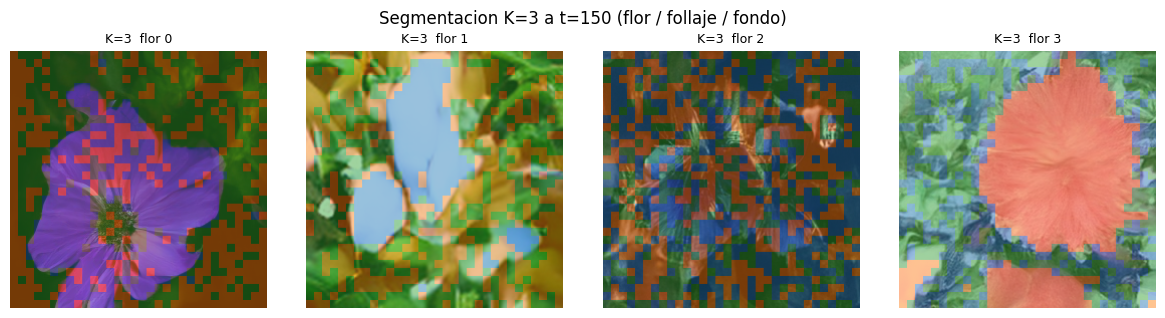

In [ ]:
K3 = 3
fig, axes = plt.subplots(1, n_flores, figsize=(3 * n_flores, 3.2))
for r in range(n_flores):
    seg = segmentar(feats_por_nivel[0][r], K=K3)      # feats de t=150
    axes[r].imshow(overlay(flores[r], seg, K3)); axes[r].axis('off')
    axes[r].set_title(f'K=3  flor {r}', fontsize=9)
fig.suptitle('Segmentacion K=3 a t=150 (flor / follaje / fondo)')
plt.tight_layout(); plt.show()